In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Iris dataset from UCI repository

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, names=columns)

# Remove completely empty rows if present
df = df.dropna(how="all")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display first five records

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [5]:
# Understand dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [6]:
# Statistical summary of numerical columns

df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
# Check duplicate records

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 3


In [9]:
# Count the number of flowers in each species

species_count = df["species"].value_counts()

print(species_count)

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [10]:
# Calculate average measurements for each species

species_average = df.groupby("species").mean(numeric_only=True)

display(species_average)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


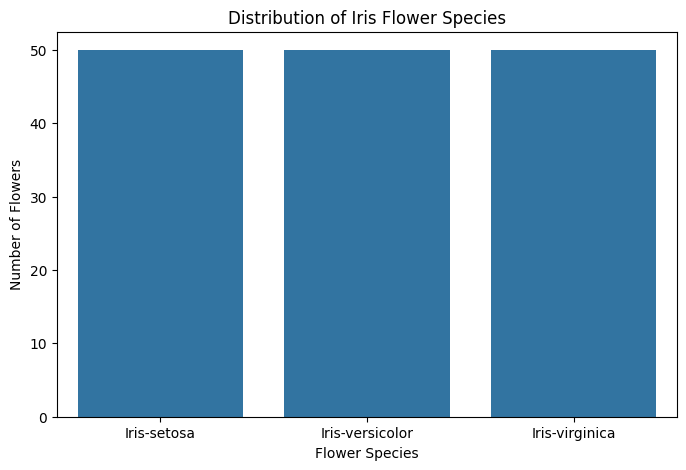

In [11]:
# Visualize flower species distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Flowers")

plt.show()

In [12]:
# Calculate correlation between numerical columns

correlation = df.select_dtypes(include="number").corr()

display(correlation)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.109369,0.871754,0.817954
sepal_width,-0.109369,1.000000,-0.420516,-0.356544
petal_length,0.871754,-0.420516,1.000000,0.962757
petal_width,0.817954,-0.356544,0.962757,1.000000


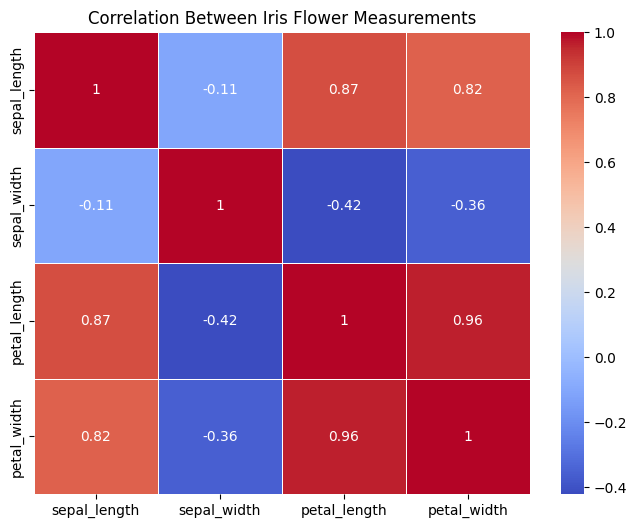

In [13]:
# Visualize correlation using a heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Between Iris Flower Measurements")

plt.show()

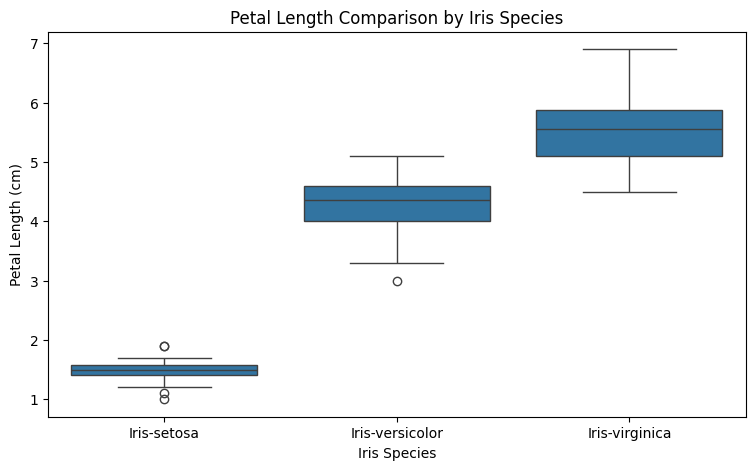

In [14]:
# Chart 1: Petal Length Comparison

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="species",
    y="petal_length"
)

plt.title("Petal Length Comparison by Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Petal Length (cm)")

plt.show()

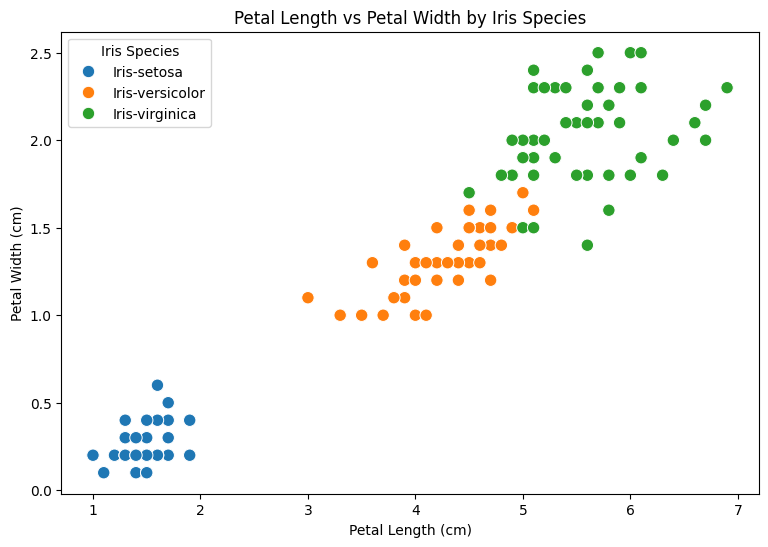

In [15]:
# Chart 2: Petal Length vs Petal Width

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    s=80
)

plt.title("Petal Length vs Petal Width by Iris Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.legend(title="Iris Species")

plt.show()

In [16]:
# Final comparison of Iris species

comparison = df.groupby("species")[
    ["sepal_length", "sepal_width",
     "petal_length", "petal_width"]
].mean()

display(comparison.round(2))

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03
